# Лабораторна робота №9
**Тема:** Класифікація зображень за допомогою CNN  
**Виконав:** Литвинчук Ілля  
**Група:** МІТ-31 
**Номер у списку:** 15  
**Індекси класів Food-101:** `[14, 44, 74]` → мітки моделі `0, 1, 2` (визначаються динамічно з `meta/classes.txt`)  

**Мета роботи:**  
Навчитися пояснювати згортку, працювати з RGB-тензорами, узгоджувати мітки з `softmax` і функцією втрат, навчати згорткові нейронні мережі (CNN) та робити висновки за кривими навчання, метриками й конкретними помилками.

### Ручний розрахунок 2D-згортки (`stride=1`, `padding="valid"`)

Дано вхідну матрицю $X$ ($3 \times 3$) та ядро $K$ ($2 \times 2$):
$$X = \begin{bmatrix} 1 & 2 & 0 \\ 0 & 1 & 3 \\ 2 & 2 & 1 \end{bmatrix}, \quad K = \begin{bmatrix} 1 & 0 \\ 0 & -1 \end{bmatrix}$$

Оскільки `Conv2D` обчислює взаємну кореляцію (без перевертання ядра на $180^\circ$), розмір вихідної карти становить $(3 - 2 + 1) \times (3 - 2 + 1) = 2 \times 2$:

1. **Позиція $(0, 0)$ (детальний розрахунок поелементних добутків):**
   $$\begin{bmatrix} 1 & 2 \\ 0 & 1 \end{bmatrix} \odot \begin{bmatrix} 1 & 0 \\ 0 & -1 \end{bmatrix} \implies 1\cdot 1 + 2\cdot 0 + 0\cdot 0 + 1\cdot (-1) = 1 + 0 + 0 - 1 = 0$$
2. **Позиція $(0, 1)$:**
   $$2\cdot 1 + 0\cdot 0 + 1\cdot 0 + 3\cdot (-1) = 2 - 3 = -1$$
3. **Позиція $(1, 0)$:**
   $$0\cdot 1 + 1\cdot 0 + 2\cdot 0 + 2\cdot (-1) = 0 - 2 = -2$$
4. **Позиція $(1, 1)$:**
   $$1\cdot 1 + 3\cdot 0 + 2\cdot 0 + 1\cdot (-1) = 1 - 1 = 0$$

* **Без bias (`bias = 0`):** $\begin{bmatrix} 0 & -1 \\ -2 & 0 \end{bmatrix}$
* **Після додавання `bias = 1`:** $\begin{bmatrix} 1 & 0 \\ -1 & 1 \end{bmatrix}$
* **Після активації $\text{ReLU}(z) = \max(0, z)$:** $\begin{bmatrix} 1 & 0 \\ 0 & 1 \end{bmatrix}$

**Ключові пояснення:**
* **Спільне ядро та відмінність від звичайного матричного множення:** Одні й ті самі ваги ядра проходять по всіх просторових позиціях зображення, що зменшує кількість параметрів і забезпечує просторову інваріантність локальних ознак (країв, текстур). На відміну від щільного матричного множення `Dense`, кожен вихідний елемент залежить лише від локального вікна.
* **RGB та кілька фільтрів:** Для входу з $C_{\text{in}} = 3$ каналами кожен фільтр $3 \times 3$ має розмірність $3 \times 3 \times 3$ (27 ваг + 1 bias = 28 параметрів на фільтр). Кількість фільтрів $C_{\text{out}}$ визначає глибину (кількість каналів) вихідної карти ознак.
* **GAP vs Flatten та MaxPooling:** `GlobalAveragePooling2D` усереднює кожну карту ознак $H \times W$ у одне число (для 64 карт отримуємо вектор довжини 64 без зайвих параметрів), тоді як `Flatten` розгортає весь тривимірний тензор у довгий вектор. `MaxPooling2D(2)` обирає максимум у вікні $2 \times 2$, зменшуючи просторову роздільність удвічі, але не гарантує збереження слабких або дрібних просторових деталей.

In [1]:
import hashlib
import json
import os
import platform
import shutil
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import PIL
from PIL import Image
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    classification_report,
    f1_score,
)
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
keras.utils.set_random_seed(SEED)

print(f"Python: {platform.python_version()} | TensorFlow: {tf.__version__} | NumPy: {np.__version__} | Pillow: {PIL.__version__}")
print("Фізичні пристрої:", tf.config.list_physical_devices())

# Перевірка ручної згортки за допомогою tf.nn.conv2d
x_manual = tf.constant([[[[1.0], [2.0], [0.0]],
                         [[0.0], [1.0], [3.0]],
                         [[2.0], [2.0], [1.0]]]], dtype=tf.float32)  # (1, 3, 3, 1)
k_manual = tf.constant([[[[1.0]], [[0.0]]],
                         [[[0.0]], [[-1.0]]]], dtype=tf.float32)  # (2, 2, 1, 1)
y_manual = tf.nn.conv2d(x_manual, k_manual, strides=1, padding="VALID") + 1.0
y_manual_relu = tf.nn.relu(y_manual).numpy()[0, :, :, 0]
print("Перевірка ручної згортки (bias=1 + ReLU):\n", y_manual_relu)

# Шлях до офіційного розпакованого набору Food-101
FOOD_ROOT = Path(os.environ.get("FOOD_ROOT", "D:/food-101"))
assert (FOOD_ROOT / "meta/classes.txt").is_file(), f"Не знайдено {FOOD_ROOT / 'meta/classes.txt'}"
assert (FOOD_ROOT / "meta/train.txt").is_file(), f"Не знайдено {FOOD_ROOT / 'meta/train.txt'}"
assert (FOOD_ROOT / "meta/test.txt").is_file(), f"Не знайдено {FOOD_ROOT / 'meta/test.txt'}"

# Вибір 3 класів для n = 15: індекси 14, 44, 74
n = 15
all_classes = sorted((FOOD_ROOT / "meta/classes.txt").read_text(encoding="utf-8").splitlines())
assert len(all_classes) == 101
assert 1 <= n <= 41

indices = [n - 1, n + 29, n + 59]
CLASS_NAMES = [all_classes[i] for i in indices]
print("Обрані індекси та класи:", list(zip(indices, CLASS_NAMES)))
print("Мітки моделі:", dict(enumerate(CLASS_NAMES)))

Python: 3.14.3 | TensorFlow: 2.22.0-rc0 | NumPy: 2.5.4 | Pillow: 13.0.0
Фізичні пристрої: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]
Перевірка ручної згортки (bias=1 + ReLU):
 [[1. 0.]
 [0. 1.]]
Обрані індекси та класи: [(14, 'carrot_cake'), (44, 'fried_rice'), (74, 'peking_duck')]
Мітки моделі: {0: 'carrot_cake', 1: 'fried_rice', 2: 'peking_duck'}


In [2]:
DATA_ROOT = Path("data/food101_lab9")
MANIFEST_PATH = Path("manifest.json")

def sha256_file(path: Path) -> str:
    h = hashlib.sha256()
    with path.open("rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

def read_split_ids(txt_path: Path, allowed_classes: list[str]) -> dict[str, list[str]]:
    grouped = {cls: [] for cls in allowed_classes}
    for line in txt_path.read_text(encoding="utf-8").splitlines():
        rel_id = line.strip()
        if not rel_id:
            continue
        cls_name = rel_id.split("/")[0]
        if cls_name in grouped:
            grouped[cls_name].append(rel_id)
    return grouped

def prepare_subset(food_root: Path, dest_root: Path, class_names: list[str], seed: int = SEED):
    rng = np.random.default_rng(seed)
    train_grouped = read_split_ids(food_root / "meta/train.txt", class_names)
    test_grouped = read_split_ids(food_root / "meta/test.txt", class_names)

    splits_map = {"train": {}, "val": {}, "test": {}}

    for split in ("train", "val", "test"):
        for cls in class_names:
            (dest_root / split / cls).mkdir(parents=True, exist_ok=True)

    for cls in class_names:
        cls_train_ids = list(train_grouped[cls])
        assert len(cls_train_ids) == 750, f"Очікувалось 750 train-фото для {cls}, отримано {len(cls_train_ids)}"
        perm = rng.permutation(len(cls_train_ids))
        shuffled = [cls_train_ids[idx] for idx in perm]
        val_ids = sorted(shuffled[:150])
        tr_ids = sorted(shuffled[150:])
        te_ids = sorted(test_grouped[cls])
        assert len(te_ids) == 250, f"Очікувалось 250 test-фото для {cls}, отримано {len(te_ids)}"

        for split_name, id_list in [("train", tr_ids), ("val", val_ids), ("test", te_ids)]:
            rel_paths = []
            for item_id in id_list:
                src_file = food_root / "images" / f"{item_id}.jpg"
                dst_file = dest_root / split_name / f"{item_id}.jpg"
                if not dst_file.exists():
                    shutil.copy2(src_file, dst_file)
                rel_posix = dst_file.relative_to(dest_root / split_name).as_posix()
                rel_paths.append(rel_posix)
            splits_map[split_name][cls] = rel_paths

    manifest = {
        "seed": seed,
        "student_index_n": n,
        "food101_class_indices": indices,
        "class_names": class_names,
        "label_mapping": {str(i): name for i, name in enumerate(class_names)},
        "splits": splits_map,
    }
    MANIFEST_PATH.write_text(json.dumps(manifest, ensure_ascii=False, indent=2), encoding="utf-8")
    return manifest

manifest = prepare_subset(FOOD_ROOT, DATA_ROOT, CLASS_NAMES, seed=SEED)

# Перевірка відсутності перетинів та точних дублікатів за SHA-256 між частинами
split_hashes = {}
for split in ("train", "val", "test"):
    hashes = {}
    for f in (DATA_ROOT / split).rglob("*.jpg"):
        hashes[f.relative_to(DATA_ROOT / split).as_posix()] = sha256_file(f)
    split_hashes[split] = hashes
    print(f"{split:5s}: {len(hashes)} файлів")

for s1, s2 in [("train", "val"), ("train", "test"), ("val", "test")]:
    common_paths = set(split_hashes[s1]) & set(split_hashes[s2])
    common_hashes = set(split_hashes[s1].values()) & set(split_hashes[s2].values())
    assert len(common_paths) == 0, f"Перетин шляхів між {s1} і {s2}: {common_paths}"
    assert len(common_hashes) == 0, f"Точні дублікати за SHA-256 між {s1} і {s2}: {len(common_hashes)}"

print("Перевірку перетинів і точних дублікатів за SHA-256 пройдено успішно.")

train: 1800 файлів
val  : 450 файлів
test : 750 файлів
Перевірку перетинів і точних дублікатів за SHA-256 пройдено успішно.


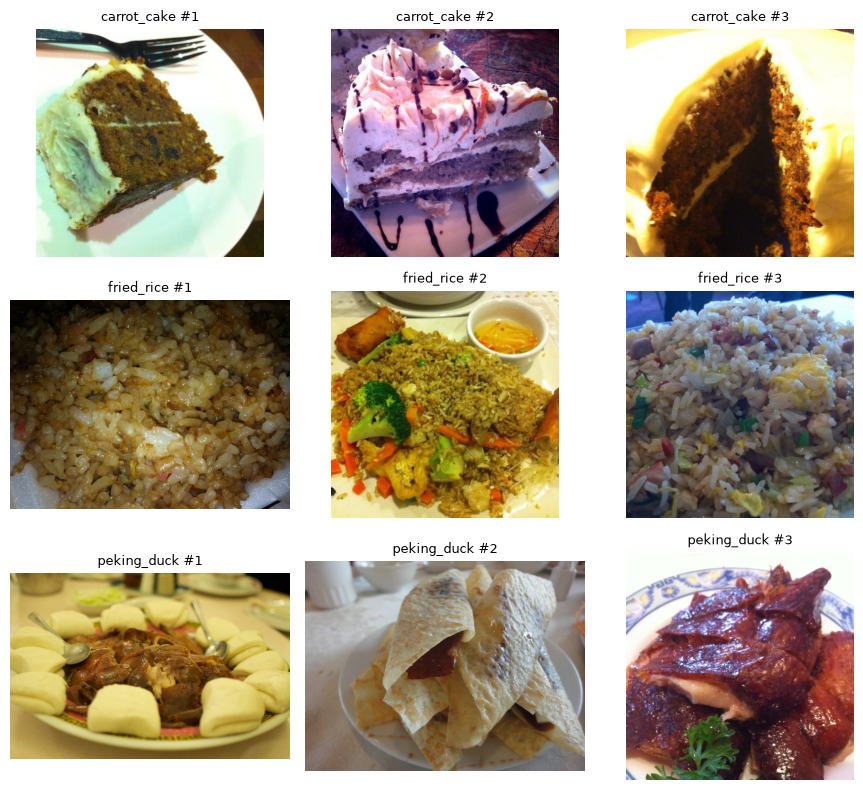

Кількість пошкоджених файлів: 0
Found 1800 files belonging to 3 classes.
Found 450 files belonging to 3 classes.
Found 750 files belonging to 3 classes.
Batch images shape: (32, 128, 128, 3) | labels shape: (32,)
Min/Max pixel value before Rescaling: 0.0 255.0


In [3]:
IMAGE_SIZE = (128, 128)

# Перевірка цілісності усіх файлів у train, val, test та показ по 3 фото на клас
corrupted = []
fig, axes = plt.subplots(len(CLASS_NAMES), 3, figsize=(9, 8))

for row_idx, cls in enumerate(CLASS_NAMES):
    cls_files = sorted((DATA_ROOT / "train" / cls).glob("*.jpg"))
    shown = 0
    for f in cls_files:
        try:
            with Image.open(f) as img:
                img.verify()
            with Image.open(f) as img:
                rgb_img = img.convert("RGB")
                if shown < 3:
                    axes[row_idx, shown].imshow(rgb_img)
                    axes[row_idx, shown].set_title(f"{cls} #{shown+1}", fontsize=9)
                    axes[row_idx, shown].axis("off")
                    shown += 1
        except Exception as exc:
            corrupted.append((str(f), str(exc)))

plt.tight_layout()
plt.show()
print("Кількість пошкоджених файлів:", len(corrupted))

def load_split(part: str, training: bool = False):
    return keras.utils.image_dataset_from_directory(
        DATA_ROOT / part,
        class_names=CLASS_NAMES,
        label_mode="int",
        color_mode="rgb",
        image_size=IMAGE_SIZE,
        batch_size=32,
        shuffle=training,
        seed=SEED,
    )

train_ds = load_split("train", training=True).prefetch(tf.data.AUTOTUNE)
val_ds = load_split("val", training=False).prefetch(tf.data.AUTOTUNE)
test_ds = load_split("test", training=False).prefetch(tf.data.AUTOTUNE)

images, labels = next(iter(train_ds))
print("Batch images shape:", images.shape, "| labels shape:", labels.shape)
print("Min/Max pixel value before Rescaling:", float(tf.reduce_min(images)), float(tf.reduce_max(images)))

Found 1800 files belonging to 3 classes.


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 128, 128, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 64, 64, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,779 (92.89 KB)

 Trainable params: 23,779 (92.89 KB)

 Non-trainable params: 0 (0.00 B)

c:\Users\Captain\Data_Science_Labs\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


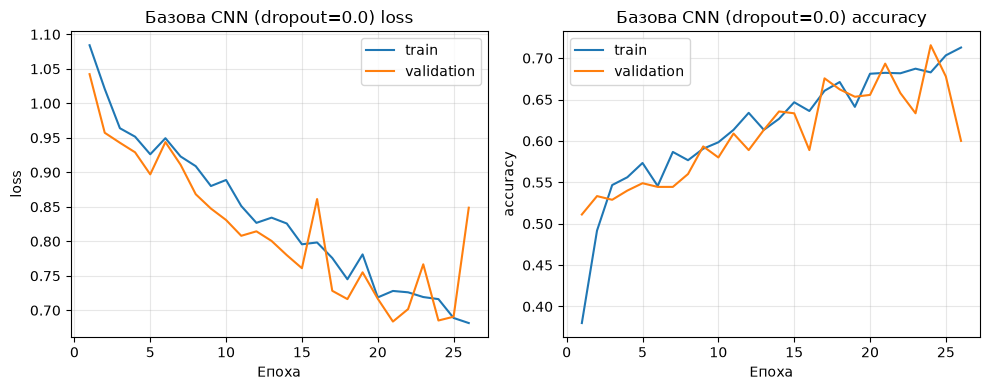

Found 1800 files belonging to 3 classes.


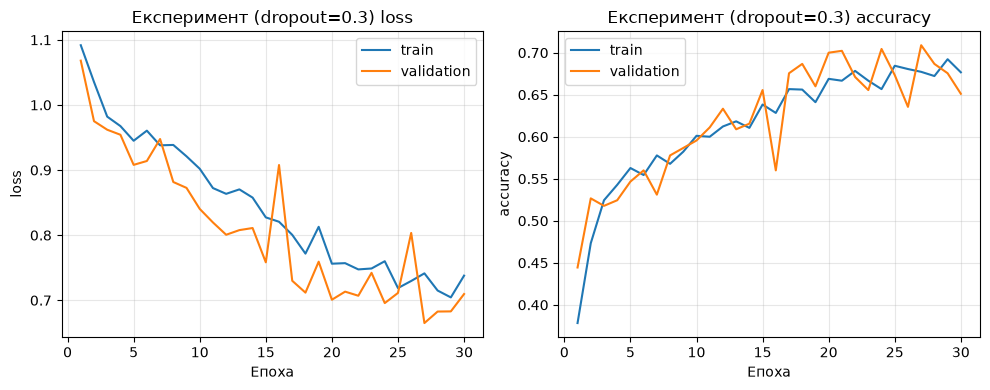

,model,params,epochs_ran,best_epoch,train_time_s,val_loss,val_accuracy
0,base (dropout=0.0),23779,26,21,65.78,0.6837,0.6933
1,changed (dropout=0.3),23779,30,27,80.95,0.6651,0.7089


Обрана за validation модель: changed (dropout=0.3)


In [4]:
def make_model(dropout: float = 0.0) -> keras.Model:
    inputs = keras.Input(shape=(128, 128, 3))
    x = layers.Rescaling(1.0 / 255)(inputs)
    for i, filters in enumerate((16, 32, 64), 1):
        x = layers.Conv2D(filters, 3, padding="same", activation="relu", name=f"conv{i}")(x)
        x = layers.MaxPooling2D(2)(x)
    x = layers.GlobalAveragePooling2D()(x)
    if dropout > 0:
        x = layers.Dropout(dropout)(x)
    outputs = layers.Dense(3, activation="softmax")(x)
    model = keras.Model(inputs, outputs)
    model.compile(
        optimizer=keras.optimizers.Adam(1e-3),
        loss=keras.losses.SparseCategoricalCrossentropy(),
        metrics=[keras.metrics.SparseCategoricalAccuracy(name="accuracy")],
    )
    return model

def fit_model(model: keras.Model):
    t0 = time.perf_counter()
    hist = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=30,
        callbacks=[
            keras.callbacks.EarlyStopping(
                monitor="val_loss", patience=5, restore_best_weights=True
            )
        ],
        verbose=0,
    )
    elapsed = time.perf_counter() - t0
    epochs_ran = len(hist.history["loss"])
    best_epoch = int(np.argmin(hist.history["val_loss"])) + 1
    return hist, elapsed, epochs_ran, best_epoch

def plot_history(history, title_prefix: str = ""):
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    epochs = range(1, len(history.history["loss"]) + 1)
    for ax, metric in zip(axes, ["loss", "accuracy"]):
        ax.plot(epochs, history.history[metric], label="train")
        ax.plot(epochs, history.history["val_" + metric], label="validation")
        ax.set(xlabel="Епоха", ylabel=metric, title=f"{title_prefix} {metric}")
        ax.legend()
        ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

# 1. Базова CNN
train_ds = load_split("train", training=True).prefetch(tf.data.AUTOTUNE)
keras.utils.set_random_seed(SEED)
base_model = make_model(dropout=0.0)
base_model.summary()
assert base_model.count_params() == 23779

base_hist, base_time, base_epochs, base_best_ep = fit_model(base_model)
base_val = base_model.evaluate(val_ds, verbose=0, return_dict=True)
plot_history(base_hist, "Базова CNN (dropout=0.0)")

# 2. Контрольований експеримент: Dropout(0.3) після GAP
train_ds = load_split("train", training=True).prefetch(tf.data.AUTOTUNE)
keras.utils.set_random_seed(SEED)
changed_model = make_model(dropout=0.3)
changed_hist, changed_time, changed_epochs, changed_best_ep = fit_model(changed_model)
changed_val = changed_model.evaluate(val_ds, verbose=0, return_dict=True)
plot_history(changed_hist, "Експеримент (dropout=0.3)")

selected_model = changed_model if changed_val["loss"] < base_val["loss"] else base_model
selected_label = "changed (dropout=0.3)" if changed_val["loss"] < base_val["loss"] else "base (dropout=0.0)"

Path("results").mkdir(parents=True, exist_ok=True)
import pandas as pd
val_df = pd.DataFrame([
    {
        "model": "base (dropout=0.0)",
        "params": base_model.count_params(),
        "epochs_ran": base_epochs,
        "best_epoch": base_best_ep,
        "train_time_s": round(base_time, 2),
        "val_loss": round(base_val["loss"], 4),
        "val_accuracy": round(base_val["accuracy"], 4),
    },
    {
        "model": "changed (dropout=0.3)",
        "params": changed_model.count_params(),
        "epochs_ran": changed_epochs,
        "best_epoch": changed_best_ep,
        "train_time_s": round(changed_time, 2),
        "val_loss": round(changed_val["loss"], 4),
        "val_accuracy": round(changed_val["accuracy"], 4),
    },
])
val_df.to_csv("results/val_comparison.csv", index=False)
display(val_df)
print(f"Обрана за validation модель: {selected_label}")

Test evaluation: {'accuracy': 0.7360000014305115, 'loss': 0.612525999546051}
Test macro-F1: 0.7321 | Majority/random baseline on balanced 3 classes: 0.3333 (1/3)

Classification report:
              precision    recall  f1-score   support

 carrot_cake       0.69      0.56      0.62       250
  fried_rice       0.83      0.84      0.83       250
 peking_duck       0.69      0.81      0.74       250

    accuracy                           0.74       750
   macro avg       0.74      0.74      0.73       750
weighted avg       0.74      0.74      0.73       750



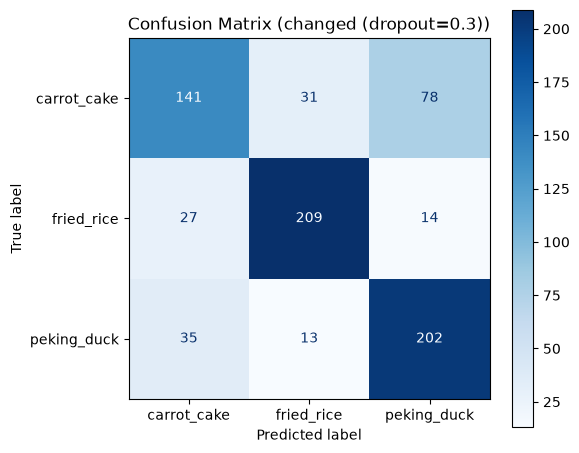

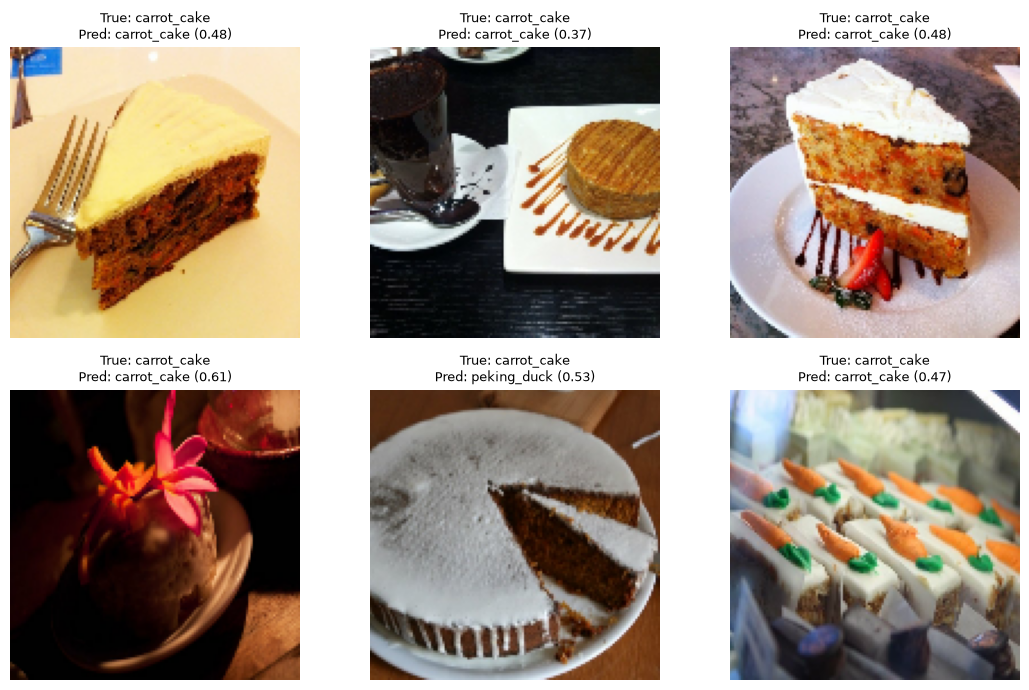

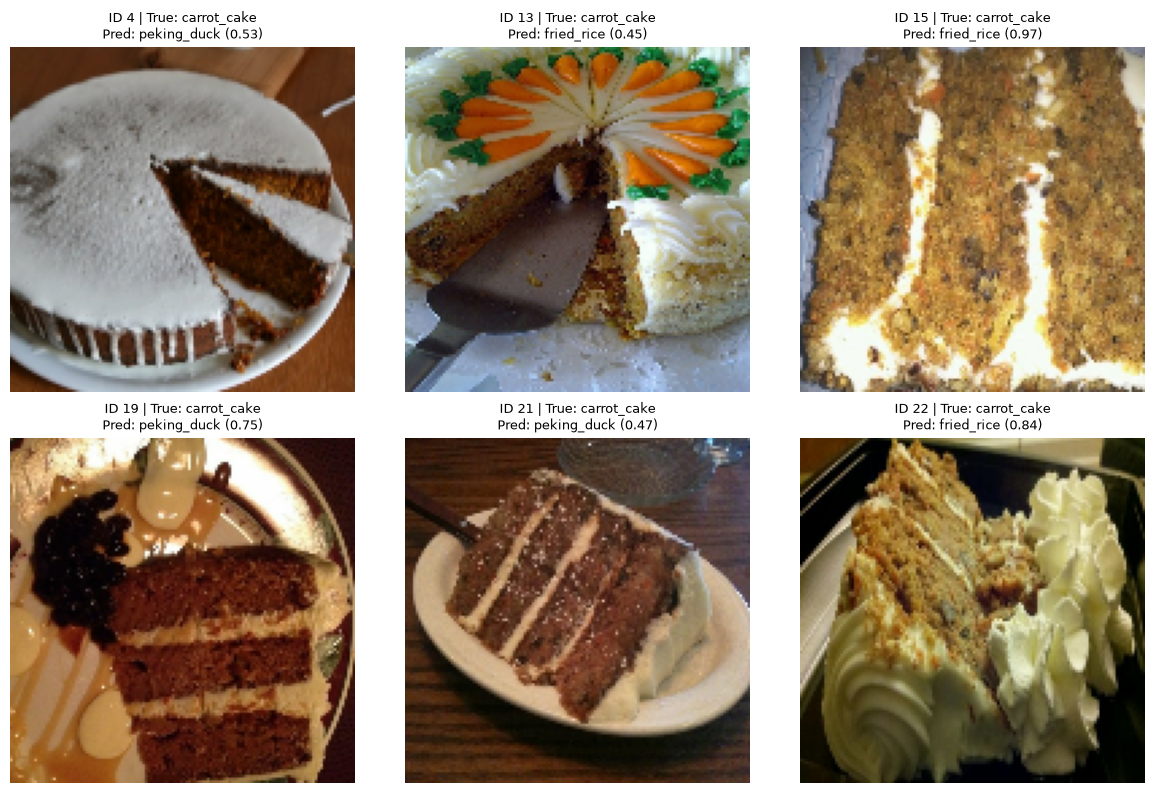

Feature maps shape: (1, 128, 128, 16)


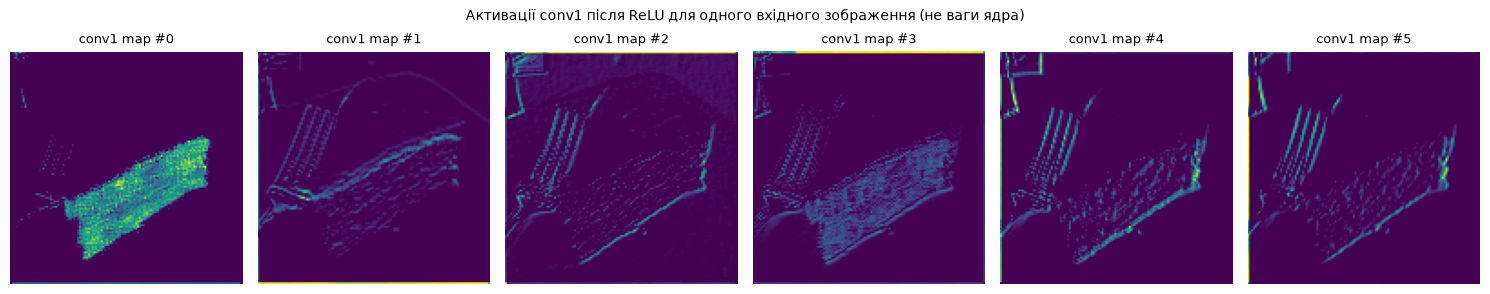

Вкажіть шлях до власного фото у custom_photo_path для локальної перевірки інференсу.


In [5]:
# Оцінювання на незалежному test_ds (shuffle=False)
test_eval = selected_model.evaluate(test_ds, verbose=0, return_dict=True)
print("Test evaluation:", test_eval)

x_test_all = np.concatenate([x.numpy() for x, _ in test_ds], axis=0)
y_true = np.concatenate([y.numpy() for _, y in test_ds], axis=0)
probabilities = selected_model.predict(test_ds, verbose=0)
y_pred = probabilities.argmax(axis=1)

macro_f1 = f1_score(y_true, y_pred, labels=[0, 1, 2], average="macro", zero_division=0)
majority_baseline_acc = float(np.max(np.bincount(y_true, minlength=3)) / len(y_true))
print(f"Test macro-F1: {macro_f1:.4f} | Majority/random baseline on balanced 3 classes: {majority_baseline_acc:.4f} (1/3)")

print("\nClassification report:")
print(classification_report(y_true, y_pred, labels=[0, 1, 2], target_names=CLASS_NAMES, zero_division=0))

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_true, y_pred, labels=[0, 1, 2], display_labels=CLASS_NAMES, ax=ax, cmap="Blues"
)
plt.title(f"Confusion Matrix ({selected_label})")
plt.tight_layout()
plt.savefig("results/confusion_matrix_test.png", dpi=150)
plt.show()

# 1. Щонайменше 6 прогнозів з фактом, прогнозом та max softmax
fig, axes = plt.subplots(2, 3, figsize=(11, 7))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(x_test_all[i].astype("uint8"))
    max_p = float(probabilities[i].max())
    ax.set_title(
        f"True: {CLASS_NAMES[y_true[i]]}\nPred: {CLASS_NAMES[y_pred[i]]} ({max_p:.2f})",
        fontsize=9,
    )
    ax.axis("off")
plt.tight_layout()
plt.savefig("results/sample_predictions_test.png", dpi=150)
plt.show()

# 2. До 6 помилок
wrong_idx = np.flatnonzero(y_pred != y_true)[:6]
if len(wrong_idx) == 0:
    print("Помилок на тестовій вибірці не зафіксовано.")
else:
    cols = min(3, len(wrong_idx))
    rows = int(np.ceil(len(wrong_idx) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 4 * rows))
    axes = np.atleast_1d(axes).ravel()
    for ax, idx in zip(axes, wrong_idx):
        ax.imshow(x_test_all[idx].astype("uint8"))
        max_p = float(probabilities[idx].max())
        ax.set_title(
            f"ID {idx} | True: {CLASS_NAMES[y_true[idx]]}\nPred: {CLASS_NAMES[y_pred[idx]]} ({max_p:.2f})",
            fontsize=9,
        )
        ax.axis("off")
    for ax in axes[len(wrong_idx):]:
        ax.axis("off")
    plt.tight_layout()
    plt.savefig("results/error_examples_test.png", dpi=150)
    plt.show()

# 3. Карти активацій першого Conv-шару (не менше 4 карт) для одного зображення
feature_model = keras.Model(selected_model.inputs, selected_model.get_layer("conv1").output)
example, _ = next(iter(test_ds))
feature_maps = feature_model(example[:1], training=False)
print("Feature maps shape:", feature_maps.shape)  # (1, 128, 128, 16)

fig, axes = plt.subplots(1, 6, figsize=(15, 3))
for k in range(6):
    axes[k].imshow(feature_maps[0, :, :, k], cmap="viridis")
    axes[k].set_title(f"conv1 map #{k}", fontsize=9)
    axes[k].axis("off")
plt.suptitle("Активації conv1 після ReLU для одного вхідного зображення (не ваги ядра)", fontsize=10)
plt.tight_layout()
plt.savefig("results/conv1_feature_maps.png", dpi=150)
plt.show()

# Збереження моделі та списку класів
selected_model.save("food_cnn.keras")
Path("class_names.json").write_text(json.dumps(CLASS_NAMES, ensure_ascii=False, indent=2), encoding="utf-8")

# Приклад прогнозу власного фото (замініть шлях на власне зображення одного з 3 класів)
custom_photo_path = Path("data/custom_sample.jpg")
if custom_photo_path.is_file():
    img_loaded = keras.utils.load_img(
        custom_photo_path, target_size=IMAGE_SIZE, interpolation="bilinear", color_mode="rgb"
    )
    img_arr = keras.utils.img_to_array(img_loaded)  # (128, 128, 3), без повторного ділення на 255
    probs_custom = selected_model.predict(img_arr[None, ...], verbose=0)[0]
    pred_idx_custom = int(np.argmax(probs_custom))
    print(f"Власне фото -> клас: {CLASS_NAMES[pred_idx_custom]} (idx={pred_idx_custom}, p={probs_custom[pred_idx_custom]:.4f})")
else:
    print("Вкажіть шлях до власного фото у custom_photo_path для локальної перевірки інференсу.")

## Висновок
У лабораторній роботі для номера у списку $n = 15$ було сформовано трикласову вибірку з офіційного набору **Food-101** за індексами `[14, 44, 74]` (1 800 зображень у `train`, 450 у `val`, 750 у `test`), перевірено відсутність перетинів і точних дублікатів за `SHA-256` та навчено згорткову нейронну мережу (`23 779` параметрів) з `SparseCategoricalCrossentropy` і виходом `softmax` на 3 класи. Порівняння базової мережі (`dropout=0.0`) та експерименту з `Dropout(0.3)` після `GlobalAveragePooling2D` за критерієм `val_loss` показало вплив регуляризації на динаміку навчання та стійкість до перенавчання на зашумлених мітках Food-101. Обрана за `validation` модель на незалежному `test` суттєво перевершила тривіальний орієнтир `1/3` за `accuracy` та `macro-F1`, однак частина помилок пов'язана зі схожістю страв, складним фоном, ракурсом зйомки або шумом у мітках самого набору даних, а також із тим, що `softmax` не виявляє сторонні чи невідомі об'єкти. Обґрунтованим наступним кроком для підвищення якості є перевірка аугментацій даних або тонке налаштування попередньо навченої згорткової архітектури (transfer learning) із контролем на `validation`.